# Characterising an exomoon with Pandora: the full fit

The companion tutorial `tutorial_detection.ipynb` shows how to *detect* a moon quickly. This tutorial takes the
next step: a **full fit** of a candidate, which gives

- the Bayesian evidence of the planet-only and the planet+moon model, with a checked accuracy (±0.2 in ln Z by default),
- the **posterior** of every parameter: what the data tell us about the moon's size, mass and orbit,
- and checks that tell you whether to trust the result.

It is written for first-time users. We use the same simulated system as in the detection tutorial: a Jupiter-like
planet with a moon around a Sun-like star, three transits observed at Kepler's 30-minute cadence.

**Steps:** simulate the light curve → detrend → likelihood and priors → the fit with `pandoramoon.NestedSampler` →
read the results → posteriors and corner plot → best-fit light curves.

In [1]:
%matplotlib inline
import time as timer
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [12, 4]

import pandoramoon as pandora
from pandoramoon.search import model_flux, cadence_times

## 1. The system and the light curve

The same system and simulation as in the detection tutorial (see there for the details). The moon has about three
Earth radii, 5 % of the planet's mass and a 5-day orbit.

In [2]:
R_sun = 696_342_000  # [m]

def make_system(with_moon=True):
    params = pandora.model_params()
    # the star: like the Sun, with quadratic limb darkening u1, u2
    params.R_star = R_sun        # [m]
    params.u1 = 0.4089
    params.u2 = 0.2556
    # the planet: a Jupiter on a one-year orbit
    params.per_bary = 365.25     # orbital period of the planet-moon barycentre [days]
    params.a_bary = 215          # semi-major axis [stellar radii]; 215 R_sun = 1 AU
    params.r_planet = 0.1        # planet radius [stellar radii]; 0.1 R_sun = 1 Jupiter radius
    params.b_bary = 0.3          # impact parameter (0 = central transit)
    params.t0_bary = 11          # time of the first transit [days]
    params.t0_bary_offset = 0.01 # small shift of that time [days]
    params.M_planet = 1.8986e27  # [kg], 1 Jupiter mass
    params.w_bary = 0            # circular orbit
    params.ecc_bary = 0
    # the moon: about 3 Earth radii, 5-day orbit, 5 % of the planet's mass
    params.r_moon = 0.03 if with_moon else 1e-6    # [stellar radii]
    params.per_moon = 5          # [days]
    params.tau_moon = 0.07       # orbital phase of the moon at the first transit [0..1]
    params.Omega_moon = 0        # orientation of the moon's orbit [deg]
    params.i_moon = 90           # inclination of the moon's orbit [deg]; 90 = seen edge-on
    params.ecc_moon = 0
    params.w_moon = 0
    params.M_moon = (0.054 if with_moon else 1e-9) * params.M_planet   # [kg]
    # observing: 3 transits, 10 days of 30-min data around each
    params.epochs = 3
    params.epoch_duration = 10   # [days]
    params.cadences_per_day = 48 # 30-min cadence
    params.epoch_distance = 365.25
    params.occult_small_threshold = 0   # exact planet-moon overlaps
    params.hill_sphere_threshold = 1.0  # moons beyond the Hill sphere are not allowed
    return params

## 2. Simulate a realistic light curve

A real light curve is never just the transit. In this tutorial we build one that has the three things you will
meet in real data:

1. **Exposure smearing.** Kepler's long-cadence data points are averages over 29.4 minutes. A planet or moon
   transit changes during that time, so each data point is a time *average* of the true brightness. We compute the
   true light curve on a fine time grid (30 sub-exposures per data point, `supersampling_factor = 30`) and average
   it, exactly as the telescope does.
2. **Stellar variability.** Stars are not constant: spots rotating with the star make slow brightness changes of a
   few hundred ppm (parts per million) over days. We add two slow waves (periods 6.3 and 13.7 days).
3. **Noise.** Photon noise is *white* (independent from point to point, here 400 ppm per 30-min point). Stars and
   instruments also add *red* noise: small wiggles that last for hours, so neighbouring points are correlated. Red
   noise is the most common source of false moon signals, so we include it (120 ppm, correlated over ~3 hours).

We keep ±5 days of data around each of the three transits, as you would cut out of a long light curve.

In [3]:
def simulate_lightcurve(params, seed=1, white_noise=400e-6, red_noise=120e-6, artefact=None):
    """Simulated 30-min light curve of `params` (a pandora.model_params) with exposure smearing,
    stellar variability, white and red noise. artefact = (epoch, offset [d], depth, duration [d]):
    an extra box-shaped dip in one transit (to imitate an instrumental glitch)."""
    rng = np.random.default_rng(seed)
    # (1) the time stamps of the data points (one every 30 min), and the true flux averaged over each exposure
    params.supersampling_factor = 1
    time = pandora.time(params).grid()
    params.supersampling_factor = 30                     # 30 sub-exposures per data point
    flux_true, _, _ = pandora.moon_model(params).light_curve(pandora.time(params).grid())
    # (2) stellar variability: two slow waves (star spots)
    star = 1 + 400e-6 * np.sin(2 * np.pi * time / 6.3 + 1.0) + 600e-6 * np.sin(2 * np.pi * time / 13.7 + 2.0)
    # (3) red noise: random wiggles correlated over ~6 data points (3 hours) ...
    a = np.exp(-1 / 6.0)
    kick = rng.normal(0, 1, len(time))
    red = np.zeros(len(time))
    for i in range(1, len(time)):
        red[i] = a * red[i - 1] + np.sqrt(1 - a * a) * kick[i]
    # ... and white noise
    flux = flux_true * (star + red_noise * red) + rng.normal(0, white_noise, len(time))
    if artefact is not None:
        epoch, offset, depth, duration = artefact
        tc = params.t0_bary + params.t0_bary_offset + epoch * params.per_bary + offset
        box = 0.25 * (1 + np.tanh((time - tc + duration / 2) / 0.02)) * (1 - np.tanh((time - tc - duration / 2) / 0.02))
        flux = flux - depth * box
    return time, flux

In [4]:
params = make_system(with_moon=True)
time, flux = simulate_lightcurve(params, seed=1)

# the moon's own contribution, without noise (for the plots below)
params.supersampling_factor = 30
_, flux_planet_true, flux_moon_true = pandora.moon_model(params).light_curve(pandora.time(params).grid())
params.supersampling_factor = 1

## 3. Remove the stellar variability (detrending)

Before fitting, we divide out the slow stellar variability. This is called *detrending*. We use `wotan` (Hippke et
al. 2019) through Pandora's helper `prepare_lightcurve`. It needs the planet's ephemeris (transit time `t0`,
period) and the transit duration T14. In a real search these come from a transit search (e.g. TLS or BLS); here
we compute T14 from the known orbit.

Two choices matter, and the helper uses the best values from our detrending study (300 injected planet+moon systems
in real Kepler light curves):

- **Mask = 1.0 × T14.** While the trend is estimated, the data within ±T14/2 of each transit are ignored, so the
  transit itself does not pull the trend down. A wider mask leaves the trend without data near the transit and adds
  noise; a narrower one lets the transit leak into the trend.
- **Window = 4.0 × T14.** The trend at each time is a robust average (`biweight`) over this window. Shorter windows
  follow the transit (and the moon) and remove part of the signal; longer windows cannot follow the star.
  4.0 × T14 is also robust when T14 is misestimated by −20 … +25 %.

The helper then keeps only the data near the transits (the *fit windows*, ±1.5 × T14 here) and measures the noise
from the detrended data *outside* those windows, where there is no signal:

- `sigma`: the white noise level (a robust standard deviation);
- `beta`: the **red-noise factor**: how much more the data scatter when averaged over T14/4 than white noise would.
  β = 1 is pure white noise; real Kepler stars have β ≈ 1.2–1.5. The error bars given to the fit are σ × β. This
  makes the fit honest about correlated wiggles: without it, red noise looks like a significant signal.

T14 = 13.7 h; sigma = 413 ppm, beta = 1.18; 249 points in the fit windows


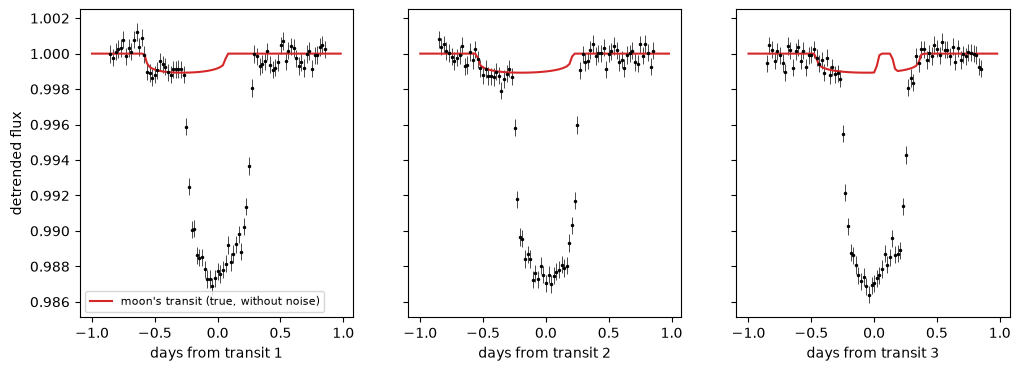

In [5]:
T14 = params.per_bary / np.pi * np.arcsin(np.sqrt((1 + params.r_planet) ** 2 - params.b_bary ** 2) / params.a_bary)
t0 = params.t0_bary + params.t0_bary_offset
lc = pandora.prepare_lightcurve(time, flux, t0=t0, period=params.per_bary, duration=T14)
print(f"T14 = {24 * T14:.1f} h; sigma = {1e6 * lc['sigma']:.0f} ppm, beta = {lc['beta']:.2f}; "
      f"{len(lc['time'])} points in the fit windows")

fig, axs = plt.subplots(1, 3, sharey=True)
for k, ax in enumerate(axs):
    tc = t0 + k * params.per_bary
    m = np.abs(lc["time"] - tc) < 1
    ax.errorbar(lc["time"][m] - tc, lc["flux"][m], lc["flux_err"][m], fmt=".", color="k", ms=3, elinewidth=0.5)
    mt = np.abs(time - tc) < 1
    ax.plot(time[mt] - tc, flux_moon_true[mt], color="C3", label="moon's transit (true, without noise)")
    ax.set_xlabel(f"days from transit {k + 1}")
axs[0].set_ylabel("detrended flux"); axs[0].legend(fontsize=8)
plt.show()

The red line is the moon's own transit (the true one, without noise). It is about 900 ppm deep, roughly twice the
noise of a single data point, and it appears at a different place in each transit, because the moon moves around the
planet between transits. The fit has to find it in the noise.

## 2. Likelihood and priors

The likelihood compares the model with the data (see the detection tutorial). The priors are Pandora's default
priors for a moon search around this planet.

In [6]:
like = pandora.Likelihood(lc["time"], lc["flux"], lc["flux_err"], epoch_distance=params.per_bary,
                          hill_sphere_threshold=1.0)
priors = pandora.default_priors(t0_bary=params.t0_bary, per_bary=params.per_bary, r_planet=0.1)
for name, prior in priors.items():
    print(f"{name:16s} {prior}")

q1               Uniform(lo=0.0, hi=1.0)
q2               Uniform(lo=0.0, hi=1.0)
R_star           Uniform(lo=557073600.0, hi=835610400.0)
per_bary         Uniform(lo=364.5195, hi=365.9805)
a_bary           LogUniform(lo=85.95973586976356, hi=537.2483491860223)
r_planet         Uniform(lo=0.05, hi=0.15000000000000002)
b_bary           Uniform(lo=0.0, hi=1.0)
t0_bary          11.0
t0_bary_offset   Uniform(lo=-0.05, hi=0.05)
M_planet         Uniform(lo=9.49065e+26, hi=2.847195e+27)
r_moon           Uniform(lo=0.010000000000000002, hi=0.06999999999999999)
per_moon         Uniform(lo=0.0, hi=69.397)
tau_moon         Uniform(lo=0.0, hi=1.0)
Omega_moon       Uniform(lo=0.0, hi=180.0)
i_moon           Uniform(lo=0.0, hi=180.0)
M_moon           Uniform(lo=0.0, hi=9.49065e+26)


## 3. The full fit: `NestedSampler`

`NestedSampler` is Pandora's built-in sampler. It fits **both** models (planet only, then planet + moon) with the
same priors for the shared parameters and returns both evidences and the Bayes factor. It runs on all cores of your
computer. You do not need to tune it; it makes its own choices and checks them:

- **Exposure smearing:** our data are 30-minute averages. With `supersampling="auto"` (the default) the fit
  computes each data point as the average of 5 sub-exposures, as the telescope does. Without this, the moon's short
  ingress and egress are blurred in the data but not in the model, and the moon's size and the Bayes factor come out
  wrong. This makes each likelihood evaluation ~3× slower, which is the price of an accurate result.
- **Convergence:** it runs many independent nested-sampling runs and adds runs until the error of ln Z is ≤ 0.1
  and the posterior is reproducible. It doubles the length of its internal sampling chains if a check shows they are
  too short, and doubles the number of live points if some runs found a solution that others missed.
- **Moon orbit coordinates:** the moon's period and phase are sampled in coordinates that follow the moon's position
  at each transit. This removes the many near-identical solutions (aliases) that make moon fits hard.

`accuracy="medium"` (default) aims at ±0.2 in ln Z; `accuracy="high"` at ±0.1 and is 2–5× slower (use it to compare
evidences at the 0.1–0.3 nat level). The planet-only model is fitted first, in seconds (importance sampling); the
planet+moon model takes minutes.
`log_dir` saves the results and every finished run; if the fit is interrupted, run it again with
`resume="resume"` and it continues where it stopped.

This cell took about 6 minutes on a 16-core computer (AMD Ryzen 9 7950X); expect 10–20 minutes on an 8-core laptop.

In [7]:
sampler = pandora.NestedSampler(like, priors, log_dir="results_characterisation", resume="overwrite", verbose=False)
t_start = timer.time()
results = sampler.run()            # accuracy="medium" (default)
print(f"run time: {(timer.time() - t_start) / 60:.1f} min")

run time: 5.9 min


## 4. Reading the results

`print_results()` shows, for each model, ln Z with its error, whether the checks passed, and every parameter (median
with the 68 % interval, mean and standard deviation). Then the Bayes factor, the epoch jackknife and notes.

In [8]:
sampler.print_results()

planet + moon: logZ = -138.789 +- 0.078   (checks passed; 29 runs x 500 live, nsteps 128, 1,037,397,382 calls, 332 s)
    q1              : 0.385565 -0.157 +0.212   (mean 0.411959, sd 0.183)
    q2              : 0.280718 -0.128 +0.202   (mean 0.316216, sd 0.177)
    R_star          : 6.94164e+08 -8.04e+07 +7.73e+07   (mean 6.93575e+08, sd 7.03e+07)
    per_bary        : 365.258 -0.00593 +0.00694   (mean 365.258, sd 0.00609)
    a_bary          : 213.454 -8.09 +7.34   (mean 213.001, sd 7.64)
    r_planet        : 0.0995673 -0.00121 +0.0016   (mean 0.0997261, sd 0.00142)
    b_bary          : 0.198753 -0.138 +0.161   (mean 0.209611, sd 0.132)
    t0_bary_offset  : -0.00701137 -0.0173 +0.0147   (mean -0.0082826, sd 0.0151)
    M_planet        : 2.19436e+27 -6.06e+26 +4.53e+26   (mean 2.13041e+27, sd 4.76e+26)
    r_moon          : 0.0311989 -0.00125 +0.00124   (mean 0.0311981, sd 0.00125)
    per_moon        : 5.53005 -0.663 +1.11   (mean 5.76956, sd 1.14)
    tau_moon        : 0.530823 

**How to read it:**

- **ln Z** of each model and **Δln Z** (the Bayes factor). The second Bayes-factor line gives the factor
  B = e^Δln Z and its category on Jeffreys' scale ("strong" from Δln Z 2.3, "very strong" from 3.45, "decisive" above
  4.6). The scale holds only if the models describe the data apart from white noise. For real light curves (stellar
  variability, changes of the transit between epochs, priors) see "Interpreting the Bayes factor" in the Fitting
  documentation, and compare with no-moon controls of the same star.
- **"checks passed"**: the sampler met its accuracy and reproducibility targets. If not, the result is still usable but
  its error is not guaranteed; the notes say why.
- **Epoch jackknife**: the fit improvement of the moon model per transit. A real moon shows up in more than one
  transit.
- **Notes**: here, that the fit used 5 sub-exposures per data point. Other notes warn, e.g., if the runs disagreed
  as if some missed a solution (`multimodal`), or if one transit dominates.

The results are also in the dictionary `results` (and as files in `log_dir`):

In [9]:
print(f"ln Z(planet + moon) = {results['logz']:.2f} +- {results['logzerr']:.2f}")
print(f"ln Z(planet only)   = {results['planet']['logz']:.2f} +- {results['planet']['logzerr']:.2f}")
print(f"Delta ln Z          = {results['dlogz']:.2f} +- {results['dlogzerr']:.2f}")
print("checks passed:", results["passed"], "| notes:", results["warnings"])

ln Z(planet + moon) = -138.79 +- 0.08
ln Z(planet only)   = -215.01 +- 0.02
Delta ln Z          = 76.22 +- 0.08
checks passed: True | notes: ["supersampling: 5 sub-exposures per cadence (cadence 30.0 min; supersampling='auto')"]


## 5. The posterior: what do we learn about the moon?

`results["samples"]` holds equally weighted samples from the posterior (one column per parameter, names in
`results["paramnames"]`). Here we compare the moon's parameters with the truth.

In [10]:
names = results["paramnames"]
S = {n: results["samples"][:, i] for i, n in enumerate(names)}
S["M_moon/M_planet"] = S["M_moon"] / S["M_planet"]
# Omega is reported on 0...180 deg (Omega and Omega + 180 deg give the same light curves at the transits). The true
# value, 0 deg, lies at the edge of that range, so for display we shift it to -90...+90 deg
S["Omega_moon"] = (S["Omega_moon"] + 90) % 180 - 90
truth = dict(r_moon=params.r_moon, per_moon=params.per_moon, i_moon=params.i_moon, Omega_moon=params.Omega_moon,
             **{"M_moon/M_planet": params.M_moon / params.M_planet}, r_planet=params.r_planet, b_bary=params.b_bary)
for n, true in truth.items():
    lo, med, hi = np.percentile(S[n], [15.87, 50, 84.13])
    print(f"{n:16s} {med:.4g}  (68 %: {lo:.4g} ... {hi:.4g})   true: {true:.4g}")

r_moon           0.0312  (68 %: 0.02995 ... 0.03244)   true: 0.03
per_moon         5.53  (68 %: 4.867 ... 6.636)   true: 5
i_moon           90.6  (68 %: 88.21 ... 92.56)   true: 90
Omega_moon       2.738  (68 %: -17.37 ... 14.62)   true: 0
M_moon/M_planet  0.1333  (68 %: 0.05366 ... 0.2394)   true: 0.054
r_planet         0.09957  (68 %: 0.09835 ... 0.1012)   true: 0.1
b_bary           0.1988  (68 %: 0.06114 ... 0.3601)   true: 0.3


Some parameters are well measured (the moon's radius and period), others less so (the mass ratio, which is measured
only through the planet's small timing wobble). Note that Ω (the orientation of the moon's orbit on the sky) is
reported on 0–180°: Ω and Ω + 180° give the same light curves at the transits, so they are folded together. Our true
value, 0°, lies at the edge of that range (0° = 180°), so in the code above we shifted Ω to −90…+90° for display. The
corner plot shows the joint posterior of the moon's parameters:

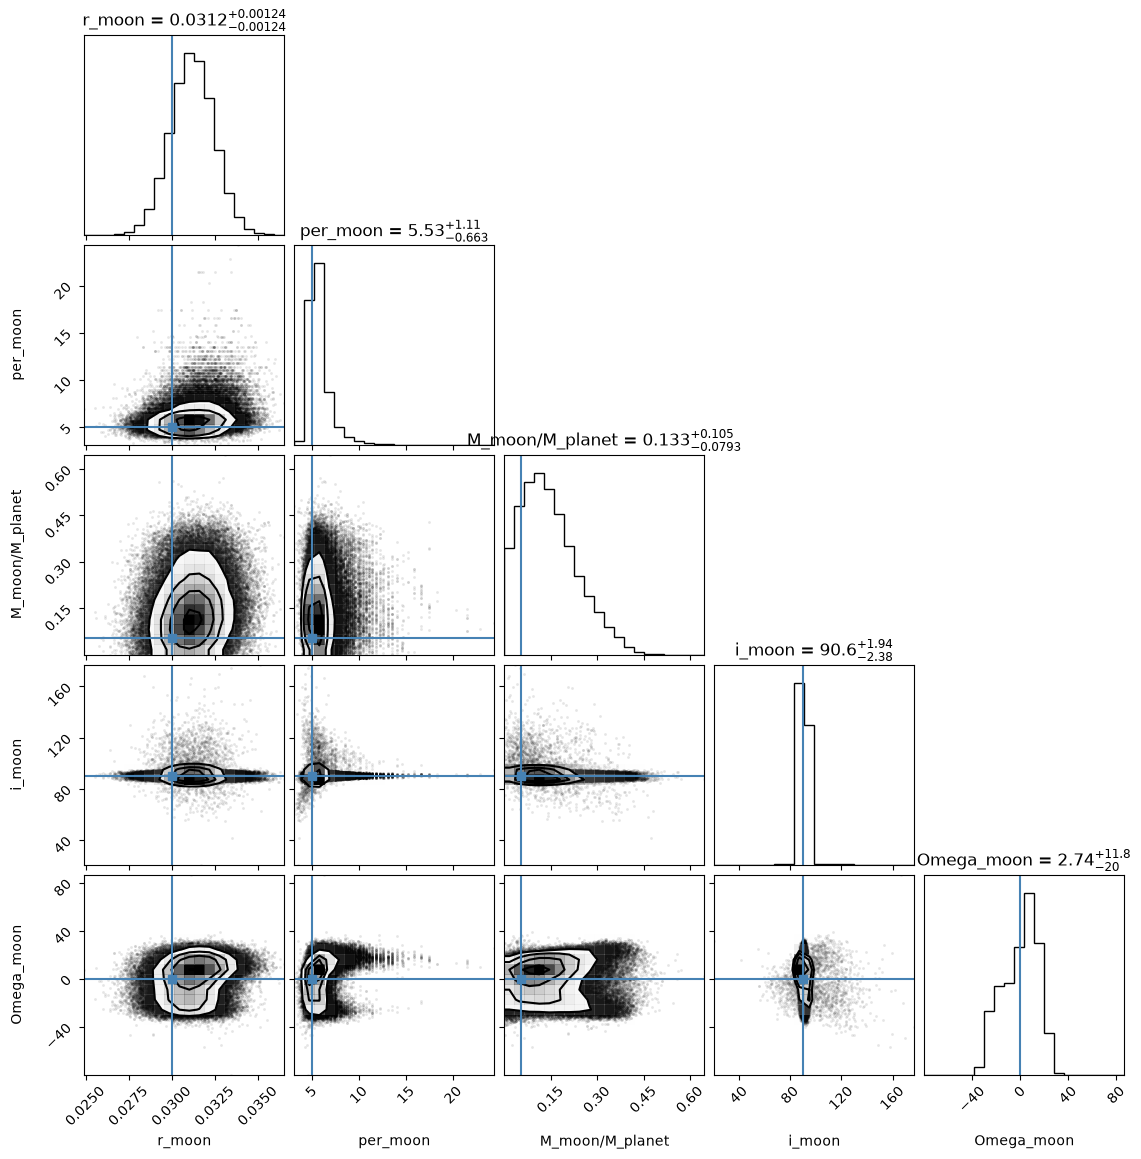

In [11]:
import corner, logging
logging.getLogger().setLevel(logging.ERROR)    # silence corner's note on sparse contour levels
keys = ["r_moon", "per_moon", "M_moon/M_planet", "i_moon", "Omega_moon"]
fig = corner.corner(np.column_stack([S[k] for k in keys]), labels=keys,
                    truths=[truth[k] for k in keys], show_titles=True, title_fmt=".3g")
plt.show()

## 6. The best-fit light curves

`sampler.parameters()` returns all 20 model parameters of the best fit (the maximum-likelihood point) as a
dictionary; `model="planet"` gives the planet-only fit. We plot both models against the data, with the residuals of
the planet-only model: the moon is what the planet-only model cannot explain.

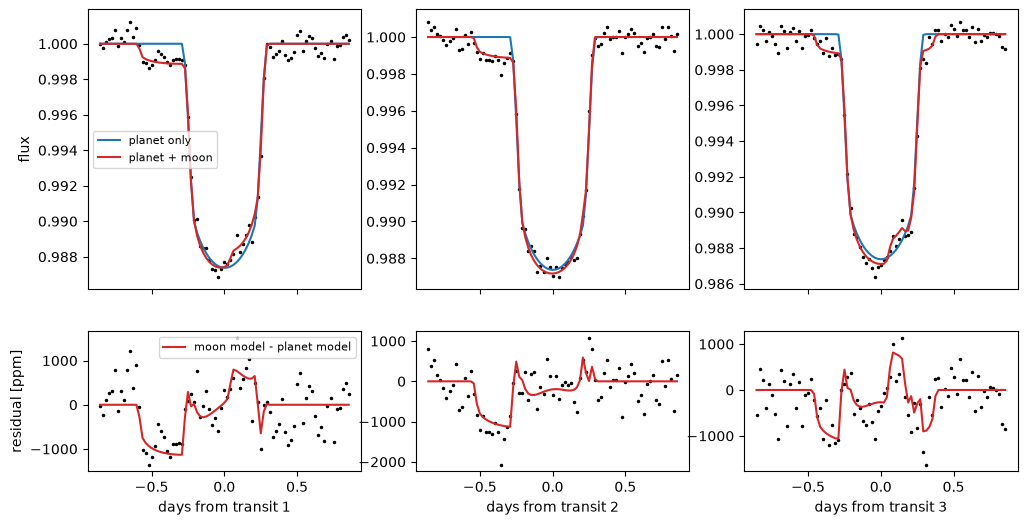

In [12]:
best_moon = sampler.parameters()
best_planet = sampler.parameters(model="planet")
L = sampler.likelihood                         # the likelihood actually used (with 5 sub-exposures)
tc = cadence_times(L)
fm, fp = model_flux(L, best_moon), model_flux(L, best_planet)

fig, axs = plt.subplots(2, 3, sharex="col", figsize=(12, 6), gridspec_kw=dict(height_ratios=[2, 1]))
for k in range(3):
    c0 = t0 + k * params.per_bary
    m = np.abs(tc - c0) < 1
    x = tc[m] - c0
    axs[0, k].plot(x, L.data[m], ".", color="k", ms=3)
    axs[0, k].plot(x, fp[m], color="C0", label="planet only")
    axs[0, k].plot(x, fm[m], color="C3", label="planet + moon")
    axs[1, k].plot(x, 1e6 * (L.data[m] - fp[m]), ".", color="k", ms=3)
    axs[1, k].plot(x, 1e6 * (fm[m] - fp[m]), color="C3", label="moon model - planet model")
    axs[1, k].set_xlabel(f"days from transit {k + 1}")
axs[0, 0].set_ylabel("flux"); axs[1, 0].set_ylabel("residual [ppm]")
axs[0, 0].legend(fontsize=8); axs[1, 0].legend(fontsize=8)
plt.show()

## 7. Good practice

- **Detect first, then characterise.** The full fit takes minutes to hours; `detect()` takes seconds.
- **Error bars:** use `prepare_lightcurve`'s σ × β (or your own honest estimate including red noise). With
  underestimated errors any wiggle becomes "significant".
- **Supersampling:** keep `supersampling="auto"` for 30-minute data. For short-cadence data (2 min) it is not needed and
  the fit skips it.
- **Priors:** the Bayes factor depends on the moon priors. Report them with the result.
- **Read the notes.** If the jackknife fails, one transit carries the signal: inspect that transit before believing
  a moon. If the runs were `multimodal`, refit with more live points (`sampler.run(nlive=2000)`).
- **Interrupted?** Create the sampler with `resume="resume"` and the same `log_dir`; finished runs are reused.

## Summary

| step | function |
|---|---|
| detrend, measure noise | `pandora.prepare_lightcurve(time, flux, t0, period, duration)` |
| likelihood | `pandora.Likelihood(time, flux, flux_err, epoch_distance=period)` |
| priors | `pandora.default_priors(t0_bary, per_bary, r_planet)` |
| full fit | `sampler = pandora.NestedSampler(like, priors); results = sampler.run()` |
| results | `sampler.print_results()`, `results["dlogz"]`, `results["samples"]`, `sampler.parameters()` |